# Voronoi-Based Path Planning

This project implements a 2D path-planning algorithm using a Voronoi-based roadmap and A* search. The goal is to find a collision-free path from a start point to a goal point while avoiding polygonal obstacles.

The notebook demonstrates the algorithm across multiple test scenarios and visualizes the generated roadmap and resulting paths.

## Problem Definition
Given a 2D environment with polygonal obstacles, a start point and a goal point,
find a collision-free path that maximizes clearance from all obstacles.

### Inputs & Outputs
- **Input:**
  - A set of polygonal obstacles $P = \{P_1, P_2, ..., P_n\}$ where each $P_{i}$ is defined by vertices in $\mathbb{R}^2$
  - Start point s ∈ $\mathbb{R}^2$
  - Goal point g ∈ $\mathbb{R}^2$
- **State:** Current position in 2D free space
- **Goal:** Reach g from s without colliding with any obstacle
- **Outputs:**
  -  A path $\pi = (v_0, v_1, ..., v_k)$ where $v_0 = s$, $v_k = g$, minimizing total length

### Mathematical Representation

The environment is modeled as a bounded 2D space:

- **Workspace:**
  $W = [0, 10] \times [0, 10] \subset \mathbb{R}^2$
- **Obstacle space:**
   $C_{obs} = P_1 \cup P_2 \cup ... \cup P_n$
  where each polygon $P_{i}$ is defined by an ordered list of vertices.
- **Free space:**
  $C_{free} = W \setminus C_{obs}$ (workspace minus obstacles)

- **Valid path:**
  $\tau(t)$ where $\tau(0) = s$, $\tau(1) = g$, and $\tau(t) \in C_{free}$ for all $t \in [0,1]$

### Voronoi-Based Model

A set of sampled points (seeds) is generated along obstacle boundaries and workspace boundaries. A Voronoi diagram is computed from these points:

- Voronoi edges represent locations equidistant from nearby obstacles  
- These edges form a structure that maximizes clearance from obstacles  

### Graph Representation

The Voronoi diagram is converted into a graph:

- **Nodes**: Valid Voronoi vertices located in free space  
- **Edges**: Valid connections between nodes that do not intersect obstacles  
- **Edge weights**: Euclidean distance between nodes  

### Pathfinding Model

The shortest path is computed using the A* algorithm:

$
f(n) = g(n) + h(n)
$


Where:
- $g(n)$: distance traveled from the start node  
- $h(n)$: estimated distance to the goal (Euclidean distance)

### Assumptions
- 2D workspace
- Obstacles are static (do not move)
- Obstacles are simple polygons (no self-intersections)
- Start and goal points lie in free space


### Constraints
- Path must not intersect any obstacle
- Path must stay within workspace bounds
- Path must be continuous from s to g
- Only valid Voronoi edges are used for navigation  


## Algorithm Selection & Theoretical Justification

### Voronoi Diagram

A Voronoi diagram is used to model the navigation space. This approach is appropriate because Voronoi edges represent points that are equidistant from nearby obstacles, resulting in paths that maximize clearance. This is particularly useful in environments with polygonal obstacles, as it naturally produces safe navigation corridors.

Additionally, the Voronoi diagram reduces the continuous space into a graph structure, enabling efficient pathfinding.

The Voronoi diagram is computed using `scipy.spatial.Voronoi`, which implements Fortune's sweep line algorithm at $O(s \log s)$ time complexity. The focus of this project is on the graph construction, geometric validation, and pathfinding built on top of it.

### A* Search Algorithm

The A* algorithm is used to compute the shortest path on the graph. A* is chosen over Dijkstra’s algorithm because it incorporates a heuristic function, improving efficiency by guiding the search toward the goal.

The heuristic used is the Euclidean distance, which is admissible and consistent, ensuring that the algorithm finds an optimal path.

### Alternatives Considered

| Approach | Pros | Cons |
|---|---|---|
| Grid A* (Cell Decomposition) | Simple to implement | Hundreds of nodes, paths hug obstacles |
| Visibility Graph | Guarantees shortest path | Paths run adjacent to obstacles, risky |
| Dijkstra's Algorithm |Guaranteed optimal path | Explores all directions equally, slower than A*
| Voronoi + A* (mine) | Maximizes clearance, optimal path | Can be inefficient in wide open spaces |

### Complexity Analysis

- **Seed sampling:** $O(n \cdot m)$ where $n$ = number of obstacles, $m$ = points per edge. More precisely $O(L/d)$ where $L$ is total obstacle perimeter and $d$ is `SAMPLE_DIST`, since points per edge depend on edge length
- **Voronoi construction:** $O(s \log s)$ where $s$ = total number of seed points
- **Edge filtering:** $O(e \cdot n)$ where $e$ = Voronoi edges, $n$ = obstacles
- **A\* search:** $O(E \log V)$ where $E$ = graph edges, $V$ = graph nodes

### Known Limitations
As noted in Russell & Norvig (2021), Voronoi-based paths can suggest unnecessary
detours in wide open spaces, since the algorithm always tries to stay equidistant
from obstacles even when no nearby obstacles exist.

## Algorithmic Implementation & Correctness

### Implementation Overview

The system is implemented as a pipeline consisting of the following stages:

1. Obstacle edge sampling to generate seed points  
2. Voronoi diagram construction using the sampled points  
3. Conversion of the Voronoi diagram into a graph structure,  filtering invalid nodes and edges
4. Connecting start and goal points to the graph  
5. Pathfinding using the A* algorithm  

Each stage is modular and implemented as separate functions, improving clarity and maintainability.


### Correctness Considerations

Correctness is ensured through multiple geometric validation steps:

- **Point-in-polygon test:** used to determine whether vertices lie inside obstacles  
- **Segment intersection test:** ensures edges do not intersect obstacle boundaries  
- **Edge validation:** combines both checks to guarantee that only valid paths are included in the graph  

These checks ensure that all generated paths remain within free space and avoid collisions.


### Handling Edge Cases

Several edge cases are explicitly handled:

- **Infinite Voronoi edges:** ridges containing `-1` are ignored to prevent invalid connections  
- **Vertices inside obstacles:** excluded from the graph to ensure valid navigation  
- **Edges crossing obstacles:** removed using geometric intersection checks  
- **Boundary constraints:** nodes and edges are restricted to the workspace bounds  
- **Start/goal connectivity:** additional logic ensures that start and goal points are connected to the graph  
- **Numerical precision issues:** tolerance thresholds (`0.01` and `0.99`) are used
  in `segments_intersect` to avoid false positives when segments share endpoints  


### Implementation Quality

The implementation is structured into reusable functions such as:

- `sample_obstacles`
- `compute_voronoi`
- `build_graph`
- `edge_is_valid`
- `astar`

This modular design improves readability, debugging, and testing, and ensures that each component can be verified independently.

## Dependencies

This project uses Python along with NumPy, SciPy, Matplotlib, and Shapely for numerical computation, Voronoi diagram construction, visualization, and geometric operations.

## Implementation
The algorithm is broken into modular functions, each handling one step of the pipeline.

In [40]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import Voronoi
import heapq
import csv
import ast
%matplotlib inline

BOUNDS = (0, 10, 0, 10)
SAMPLE_DIST = 0.3

### Step 1: Environment & Sampling
Points are sampled densely along obstacle edges to use as Voronoi seeds.

In [41]:
# Sample points along the edges of the obstacles
def sample_edge(p1, p2, dist=SAMPLE_DIST):
    # Convert to numpy arrays, compute the Euclidean distance and number of samples needed
    p1, p2 = np.array(p1), np.array(p2)
    length = np.linalg.norm(p2 - p1)
    n = max(2, int(length / dist))

    # Generate points along the edge from p1 to p2
    return [p1 + (p2 - p1) * t / (n - 1) for t in range(n)]

# Sample points along all obstacle edges and add boundary seeds
def sample_obstacles(obstacles):
    seeds = []

    # Sample points along each edge of the obstacles
    for poly in obstacles:
        for i in range(len(poly)):
            p1 = poly[i]
            p2 = poly[(i + 1) % len(poly)]
            seeds.extend(sample_edge(p1, p2))

     # Add boundary seeds to contain the Voronoi diagram
    xmin, xmax, ymin, ymax = BOUNDS
    for x in np.linspace(xmin, xmax, 15):
        seeds.append([x, ymin])
        seeds.append([x, ymax])
    for y in np.linspace(ymin, ymax, 15):
        seeds.append([xmin, y])
        seeds.append([xmax, y])
    return seeds

### Step 2: Geometry Helpers
Used to filter invalid Voronoi edges.

In [42]:
# Check if a point is inside a polygon using the ray-casting algorithm
def point_in_polygon(point, polygon):
    x, y = point
    n = len(polygon)
    inside = False
    # Start with the last vertex and loop through each edge of the polygon
    px, py = polygon[-1]
    for i in range(n):
        cx, cy = polygon[i]
        # Check if the horizontal ray from the point intersects with the edge (px, py) to (cx, cy)
        if ((cy > y) != (py > y)) and (x < (px - cx) * (y - cy) / (py - cy) + cx):
            inside = not inside
        px, py = cx, cy
    return inside

# Check if two line segments (p1-p2 and p3-p4) intersect using cross products and parameterization
def segments_intersect(p1, p2, p3, p4):
    d1 = np.array(p2) - np.array(p1)
    d2 = np.array(p4) - np.array(p3)
    cross = d1[0] * d2[1] - d1[1] * d2[0]
    if abs(cross) < 1e-10:
        return False
    diff = np.array(p3) - np.array(p1)
    t = (diff[0] * d2[1] - diff[1] * d2[0]) / cross
    u = (diff[0] * d1[1] - diff[1] * d1[0]) / cross
    # We use a small margin (0.01) to avoid counting near-tangential edges as intersecting
    return 0.01 < t < 0.99 and 0.01 < u < 0.99

# Check if the edge between points a and b is valid
def edge_is_valid(a, b, obstacles):
    mid = ((a[0] + b[0]) / 2, (a[1] + b[1]) / 2)
    xmin, xmax, ymin, ymax = BOUNDS

    # Check if the midpoint of the edge is within the bounds of the environment
    if not (xmin <= mid[0] <= xmax and ymin <= mid[1] <= ymax):
        return False

    # Check if the midpoint is inside any obstacle or if the edge intersects with any obstacle edge
    for poly in obstacles:
        if point_in_polygon(mid, poly):
            return False
        for i in range(len(poly)):
            wall_a = poly[i]
            wall_b = poly[(i + 1) % len(poly)]
            if segments_intersect(a, b, wall_a, wall_b):
                return False
    return True

### Step 3: Voronoi Graph Construction

In [43]:
# Compute the Voronoi diagram from the sampled seeds using scipy.spatial.Voronoi
def compute_voronoi(seeds):
    seeds_np = np.array(seeds)
    vor = Voronoi(seeds_np)
    return vor

# Build a graph from the Voronoi vertices and edges, filtering out those that are inside obstacles or out of bounds
def build_graph(vor, obstacles):
    nodes = []
    edges = []
    node_map = {}

    xmin, xmax, ymin, ymax = BOUNDS

    # Iterate through Voronoi vertices and add valid ones as graph nodes
    for vi, v in enumerate(vor.vertices):
        inside_any = any(point_in_polygon(v, poly) for poly in obstacles)
        in_bounds = xmin <= v[0] <= xmax and ymin <= v[1] <= ymax
        if not inside_any and in_bounds:
            node_map[vi] = len(nodes)
            nodes.append(tuple(v))

    for ridge in vor.ridge_vertices:
        # Skip ridges that have infinite vertices (-1)
        if -1 in ridge:
            continue
        a_vi, b_vi = ridge

        # Only consider edges where both vertices are valid nodes in our graph
        if a_vi not in node_map or b_vi not in node_map:
            continue
        a = vor.vertices[a_vi]
        b = vor.vertices[b_vi]

        # Check if the edge between a and b is valid
        if edge_is_valid(a, b, obstacles):

            # Map the Voronoi vertex indices to our graph node indices
            ai = node_map[a_vi]
            bi = node_map[b_vi]

            # Compute the length of the edge and add it to the graph
            dist = np.linalg.norm(np.array(a) - np.array(b))
            edges.append((ai, bi, dist))

    return nodes, edges

# Connect a point (start or goal) to the graph by finding the nearest valid node and adding an edge
def connect_point(point, nodes, edges, obstacles):
    # Assign a new index for the point and add it to the list of nodes
    point_idx = len(nodes)
    nodes = list(nodes) + [point]

    # Compute distances from the point to all existing nodes and sort them
    dists = [(np.linalg.norm(np.array(point) - np.array(n)), i) for i, n in enumerate(nodes[:-1])]
    dists.sort()

    # Connect the point to the nearest valid node in the graph
    for dist, i in dists:
        if edge_is_valid(point, nodes[i], obstacles):
            edges.append((point_idx, i, dist))
            break

    return nodes, edges, point_idx

### Step 4: A* Search

In [44]:
# Implement A* pathfinding algorithm
def astar(nodes, edges, start_idx, goal_idx):
    # Build adjacency list
    adj = {i: [] for i in range(len(nodes))}
    for a, b, d in edges:
        adj[a].append((b, d))
        adj[b].append((a, d))

    # Heuristic function: Euclidean distance from node i to the goal
    def h(i):
        return np.linalg.norm(np.array(nodes[i]) - np.array(nodes[goal_idx]))

    # Open set is a priority queue of (f, node_index, path_to_node)
    open_set = [(h(start_idx), start_idx, [start_idx])]

    # Visited set to keep track of explored nodes
    visited = set()

    # While there are nodes to explore in the open set
    while open_set:
        # Pop the node with the lowest f value
        f, current, path = heapq.heappop(open_set)
        if current in visited:
            continue
        visited.add(current)

        # If we have reached the goal, return the path as a list of coordinates
        if current == goal_idx:
            return [nodes[i] for i in path]

        # Calculate g value (cost from start to current) and explore neighbors
        g = f - h(current)
        for neighbor, edge_dist in adj[current]:
            if neighbor not in visited:
                new_g = g + edge_dist
                new_f = new_g + h(neighbor)
                heapq.heappush(open_set, (new_f, neighbor, path + [neighbor]))

    return None


### Step 5: Visualization & Run function

In [45]:
# Draw obstacles as filled polygons
def draw_obstacles(ax, obstacles):
    for poly in obstacles:
        # Extract x and y coordinates for plotting
        xs = [p[0] for p in poly] + [poly[0][0]]
        ys = [p[1] for p in poly] + [poly[0][1]]

        # Fill the polygon with a color and outline it
        ax.fill(xs[:-1], ys[:-1], color='blue', alpha=0.3)
        ax.plot(xs, ys, 'b-')

# Main function to run the pathfinding algorithm on a given scenario and visualize the results
def run(obstacles, start, goal,save_path=None):
    seeds = sample_obstacles(obstacles)
    vor = compute_voronoi(seeds)
    nodes, edges = build_graph(vor, obstacles)
    nodes, edges, start_idx = connect_point(start, nodes, edges, obstacles)
    nodes, edges, goal_idx = connect_point(goal, nodes, edges, obstacles)
    path = astar(nodes, edges, start_idx, goal_idx)

    # Plot 1 - Obstacles + Seeds
    fig1, ax1 = plt.subplots(figsize=(7, 6))
    fig1.suptitle('Step 1: Obstacle Edge Sampling', fontsize=12)
    draw_obstacles(ax1, obstacles)
    ax1.scatter(*start, c='green', s=100, zorder=5, label='Start')
    ax1.scatter(*goal, c='red', s=100, zorder=5, marker='*', label='Goal')
    ax1.annotate('Start', start, textcoords='offset points', xytext=(6, 4), fontsize=8, color='#22c48a')
    ax1.annotate('Goal', goal, textcoords='offset points', xytext=(6, 4), fontsize=8, color='#F87D3E')
    seed_xs = [s[0] for s in seeds]
    seed_ys = [s[1] for s in seeds]
    ax1.scatter(seed_xs, seed_ys, c='orange', s=8, zorder=3, alpha=0.6, label='Seeds')
    ax1.set_xlim(0, 10)
    ax1.set_ylim(0, 10)
    ax1.grid(True, alpha=0.3)
    ax1.legend(fontsize=8, loc='upper right')
    plt.show()

    # Plot 2 - Graph + Path
    fig2, ax2 = plt.subplots(figsize=(7, 6))
    fig2.suptitle('Step 2: Voronoi Graph + A* Path', fontsize=12)
    draw_obstacles(ax2, obstacles)
    ax2.scatter(*start, c='green', s=100, zorder=5, label='Start')
    ax2.scatter(*goal, c='red', s=100, zorder=5, marker='*', label='Goal')
    ax2.annotate('Start', start, textcoords='offset points', xytext=(6, 4), fontsize=8, color='#22c48a')
    ax2.annotate('Goal', goal, textcoords='offset points', xytext=(6, 4), fontsize=8, color='#F87D3E')
    for ai, bi, _ in edges:
        a, b = nodes[ai], nodes[bi]
        ax2.plot([a[0], b[0]], [a[1], b[1]], 'cyan', linewidth=0.8, alpha=0.4)
    if path:
        px = [p[0] for p in path]
        py = [p[1] for p in path]
        ax2.plot(px, py, color='purple', linewidth=2.5, zorder=4, label='A* Path')
    ax2.set_xlim(0, 10)
    ax2.set_ylim(0, 10)
    ax2.grid(True, alpha=0.3)
    ax2.legend(fontsize=8, loc='upper right')
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    
    plt.show()

    if path:
        path_len = sum(np.linalg.norm(np.array(path[i+1]) - np.array(path[i])) for i in range(len(path)-1))
        print(f"  Obstacles:     {len(obstacles)}")
        print(f"  Seeds:         {len(seeds)}")
        print(f"  Graph nodes:   {len(nodes)}")
        print(f"  Graph edges:   {len(edges)}")
        print(f"  Path waypoints:{len(path)}")
        print(f"  Path length:   {path_len:.2f}")
    else:
        print("  No valid path found!")

    return path

## Complexity Analysis & Optimization

### Time Complexity

| Step | Complexity | Explanation |
|---|---|---|
| Seed sampling | $O(n \cdot m)$ | $n$ = obstacles, $m$ = points per edge. More precisely $O((L + B)/d)$ where $L$ is total obstacle perimeter, $B$ is workspace boundary perimeter (constant 40 for a 10×10 grid), and $d$ is `SAMPLE_DIST`. Since $B$ is fixed, this simplifies to $O(L/d)$ asymptotically. |
| Voronoi construction | $O(s \log s)$ | $s$ = total seed points, SciPy computes the diagram using a robust computational geometry implementation |
| Edge filtering | $O(e \cdot n)$ | $e$ = Voronoi edges, each checked against $n$ obstacles |
| A* search | $O(E \log V)$ | $E$ = graph edges, $V$ = nodes, log factor from priority queue |

### Space Complexity

| Component | Complexity | Explanation |
|---|---|---|
| Voronoi graph | $O(s)$ | Vertices and edges scale linearly with seed count |
| A* open set | $O(V)$ | Worst case stores all nodes in priority queue |

### Overall
The dominant cost is Voronoi construction at $O(s \log s)$. Since $s$ is controlled
by `SAMPLE_DIST`, there is a direct tradeoff between path quality and computation speed.

### Optimizations Implemented

- **Boundary seeds:** added along workspace edges to contain the Voronoi diagram
  and prevent infinite edges, reducing the number of invalid ridges to filter
- **Midpoint checking:** `edge_is_valid` checks the midpoint rather than endpoints,
  avoiding false rejections of edges that touch obstacle boundaries
- **Early termination in A\*:** search stops immediately when goal is reached,
  not when all nodes are explored
- **SAMPLE_DIST parameter:** controls seed density, directly trading path smoothness
  for computation speed - lower value = smoother path but more seeds and slower Voronoi construction
- **Modular filtering:** invalid nodes are removed before edge processing in
  `build_graph`, reducing the number of edges that need to be checked
- **Ignoring infinite Voronoi edges:** ridges containing `-1` are skipped early, avoiding unnecessary geometric checks on invalid edges
- **A\* instead of Dijkstra:** the Euclidean distance heuristic guides search toward
  the goal, reducing nodes explored compared to Dijkstra's uniform expansion, while still guaranteeing an optimal path

### Potential Improvements

- **Path smoothing:** after A* finds a path, attempt to shortcut between
  non-adjacent waypoints if a direct line between them is collision-free.
  This would reduce unnecessary zigzagging along the Voronoi edges.

- **Connecting to k nearest nodes:** currently start and goal connect to only
  the single nearest valid node. Connecting to k nearest nodes would make the
  graph more robust in complex environments.

- **3D extension:** the algorithm extends naturally to 3D by replacing polygon
  obstacles with polyhedra and using 3D Voronoi construction, enabling robot
  motion planning in three-dimensional space.

- **Dynamic obstacles:** the current implementation assumes static obstacles.
  Replanning when obstacles move would make the system applicable to real-world
  robotics scenarios.

## Experimentation, Testing & Evaluation

The algorithm was tested on multiple environments to evaluate correctness, robustness, and performance. Each test case includes different obstacle layouts such as simple obstacles, narrow corridors, blocked paths, and dense obstacle environments.

### Scenario 1: Basic Environment
This case tests whether the algorithm can find a collision-free path around simple polygonal obstacles.

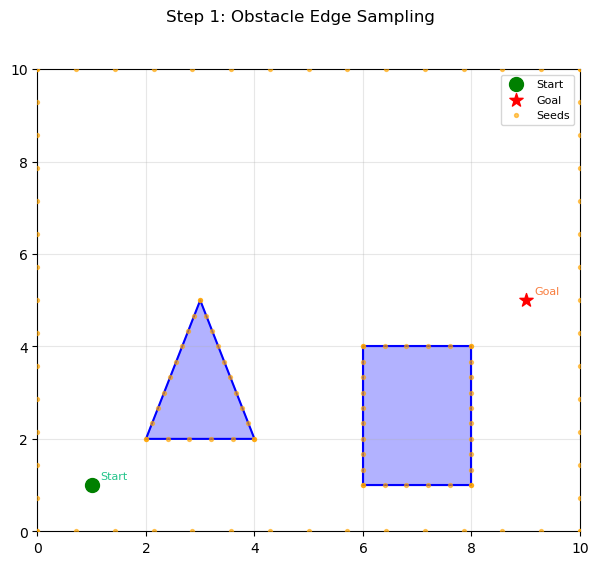

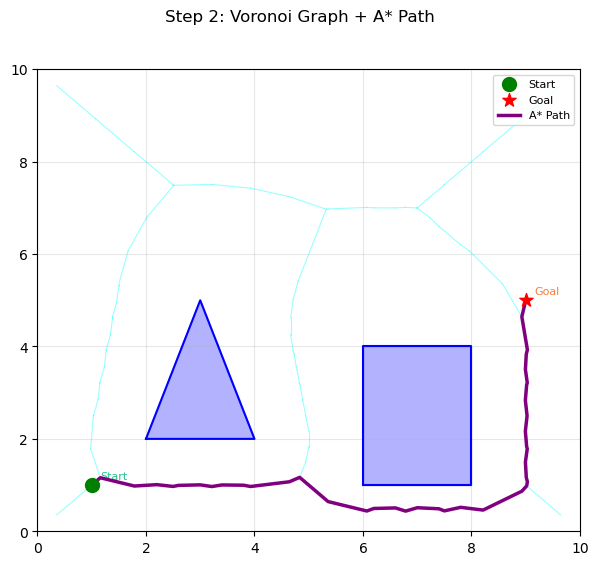

  Obstacles:     2
  Seeds:         118
  Graph nodes:   101
  Graph edges:   102
  Path waypoints:41
  Path length:   12.67


In [46]:
# Scenario 1 - Basic: triangle and rectangle
obstacles = [
    [(2, 2), (4, 2), (3, 5)],
    [(6, 1), (8, 1), (8, 4), (6, 4)],
]
start = (1, 1)
goal = (9, 5)
run(obstacles, start, goal);

### Scenario 2: Narrow Passage
This case tests whether the algorithm can handle a narrow corridor between obstacles. It evaluates the effect of obstacle sampling and whether the Voronoi graph can still produce a valid path through limited free space.

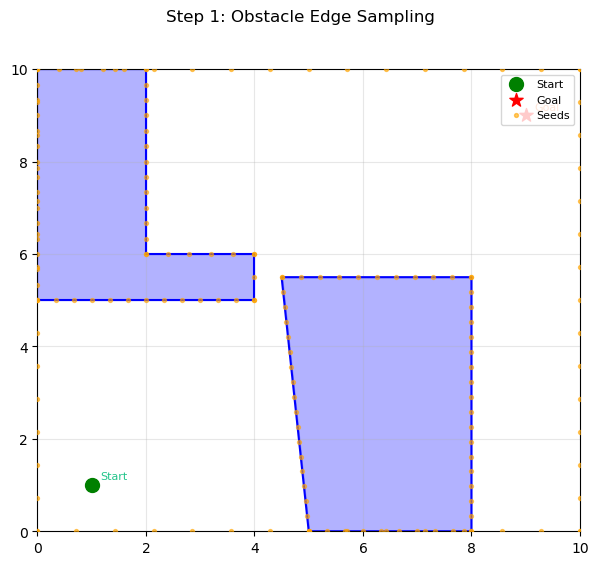

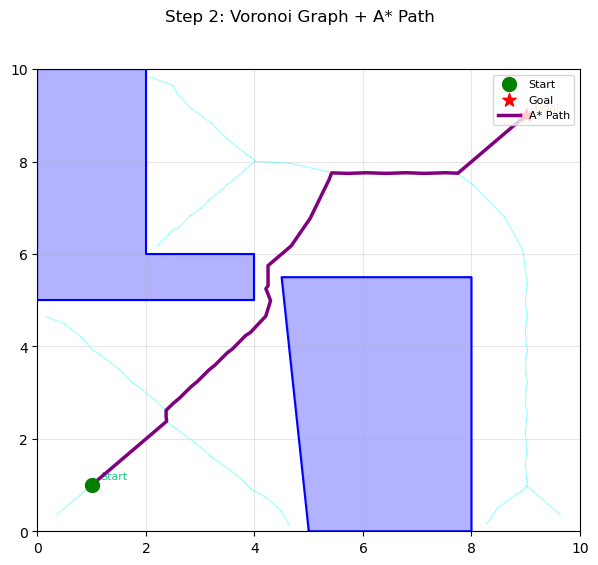

  Obstacles:     2
  Seeds:         174
  Graph nodes:   114
  Graph edges:   113
  Path waypoints:39
  Path length:   12.52


In [47]:
# Scenario 2 - Narrow corridor: two obstacles
obstacles = [
    [(0, 5), (4, 5), (4, 6), (2, 6), (2, 10), (0, 10)],
    [(5, 0), (8, 0), (8, 5.5), (4.5, 5.5)],
]
start = (1, 1)
goal = (9, 9)
run(obstacles, start, goal);

### Scenario 3: Mixed Obstacle Shapes

This scenario includes multiple obstacles with different shapes (a pentagon, triangle, and rectangle). It tests whether the algorithm can handle irregular geometries and generate a valid path through a non-uniform environment.

The case evaluates the robustness of the Voronoi construction and graph filtering, ensuring that the algorithm correctly navigates around obstacles of varying shapes and orientations.

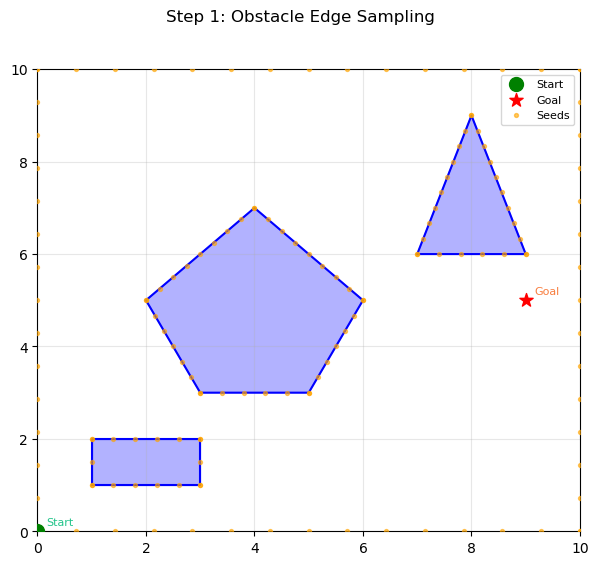

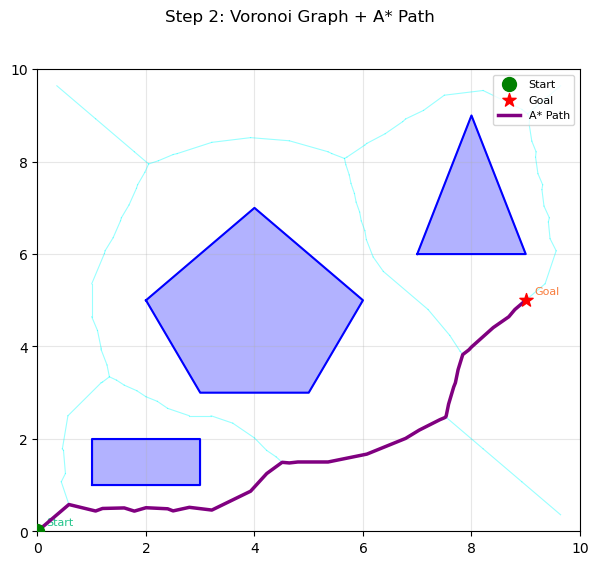

  Obstacles:     3
  Seeds:         142
  Graph nodes:   128
  Graph edges:   130
  Path waypoints:36
  Path length:   11.51


In [48]:
# Scenario 3 - Three obstacles: pentagon, triangle, rectangle
obstacles = [
    [(2, 5), (3, 3), (5, 3), (6, 5), (4, 7)],
    [(7, 6), (9, 6), (8, 9)],
    [(1, 1), (3, 1), (3, 2), (1, 2)],
]
start = (0, 0)
goal = (9, 5)
run(obstacles, start, goal);

### Scenario 4: Vertical Barriers

This scenario includes obstacles arranged to form vertical barriers between the start and goal positions. It tests whether the algorithm can correctly navigate around blocking structures rather than attempting invalid direct paths.

The case evaluates the effectiveness of edge validation and graph construction, ensuring that paths do not intersect obstacle boundaries and that the algorithm finds an alternative route around the barriers.

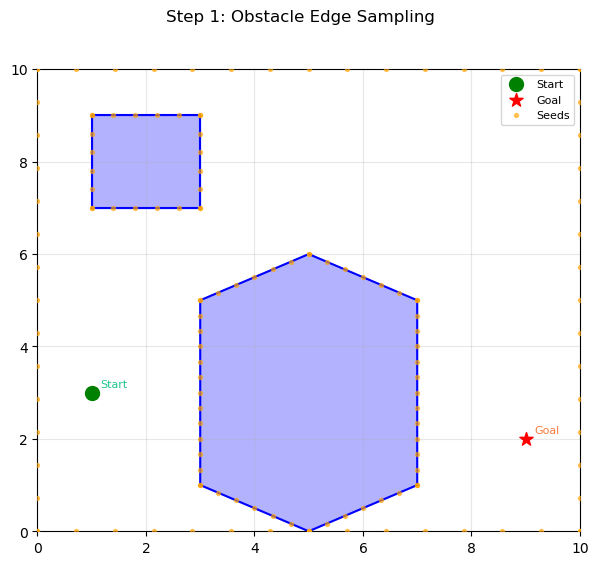

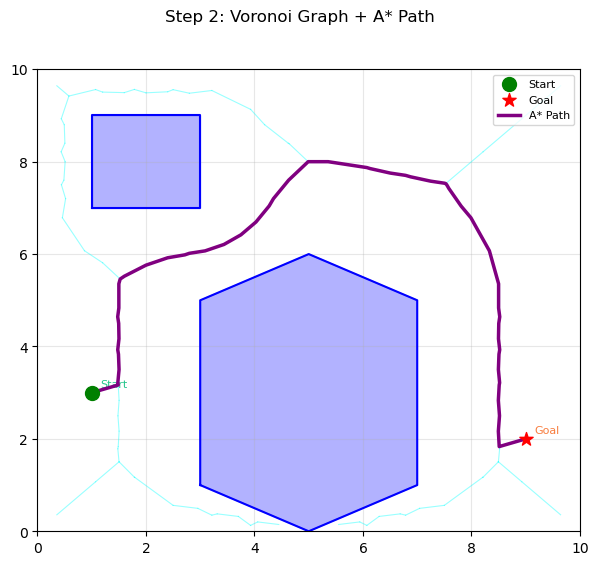

  Obstacles:     2
  Seeds:         138
  Graph nodes:   117
  Graph edges:   117
  Path waypoints:54
  Path length:   16.33


In [49]:
# Scenario 4 - Vertical walls: hexagon and rectangle
obstacles = [
    [(3, 1), (5, 0), (7, 1), (7, 5), (5, 6), (3, 5)],
    [(1, 7), (3, 7), (3, 9), (1, 9)],
]
start = (1, 3)
goal = (9, 2)
run(obstacles, start, goal);

### Scenario 5: Diagonal Path with Irregular Obstacles

This scenario tests pathfinding along a diagonal direction from the start to the goal while navigating around irregularly shaped obstacles.

This evaluates whether the Voronoi-based graph and A* search can produce efficient paths in non-linear directions while correctly avoiding obstacles.

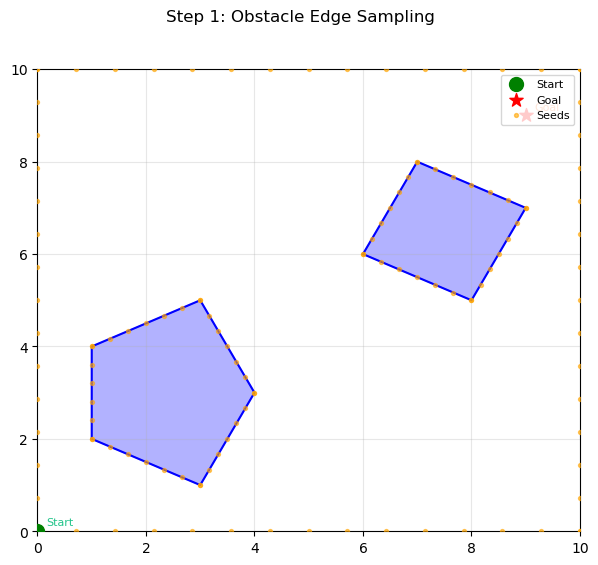

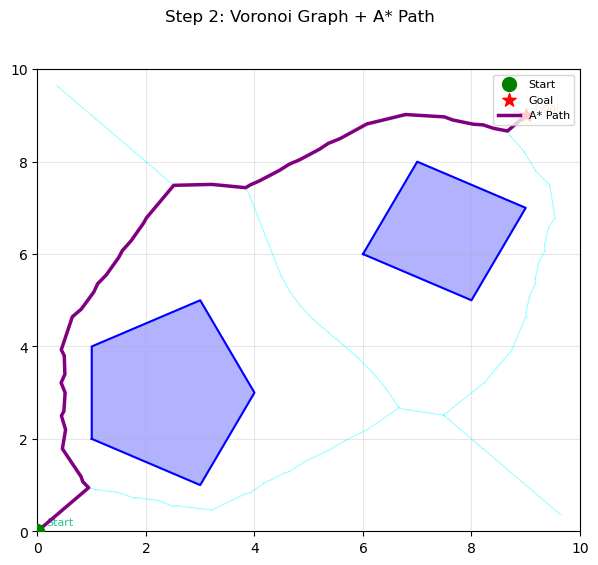

  Obstacles:     2
  Seeds:         122
  Graph nodes:   104
  Graph edges:   105
  Path waypoints:45
  Path length:   15.78


In [50]:
# Scenario 5 - Diagonal path: irregular polygon and triangle
obstacles = [
    [(1, 2), (3, 1), (4, 3), (3, 5), (1, 4)],
    [(6, 6), (8, 5), (9, 7), (7, 8)],
]
start = (0, 0)
goal = (9, 9)
run(obstacles, start, goal);

### Scenario 6: No Valid Path
This scenario tests the algorithm’s ability to correctly detect failure. Since the obstacle blocks the workspace, the algorithm should return no path instead of producing an invalid route.

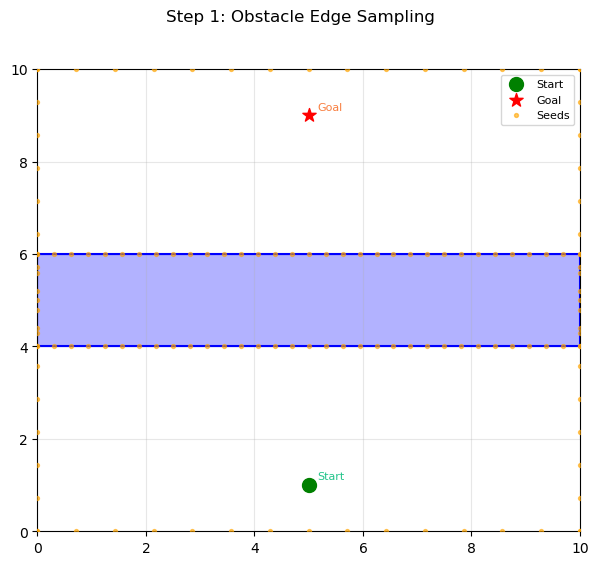

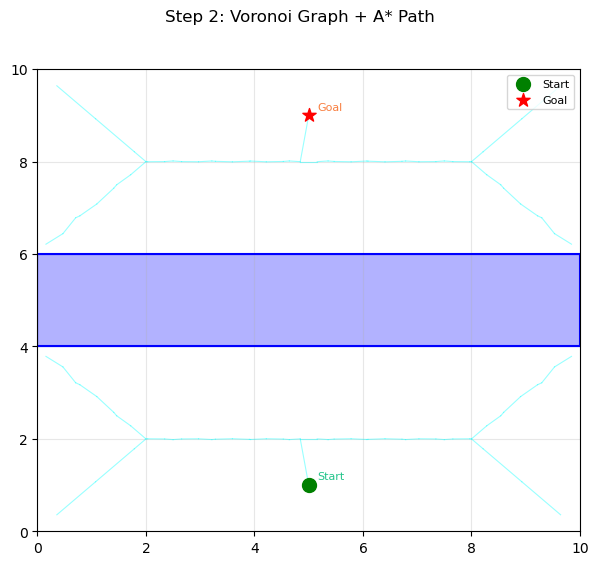

  No valid path found!


In [51]:
# Scenario 6 - Blocked: wall spanning full width
obstacles = [
    [(0, 4), (10, 4), (10, 6), (0, 6)],
]
start = (5, 1)
goal = (5, 9)
run(obstacles, start, goal);

### Scenario 7: Dense Obstacle Environment
This case tests the algorithm in a more cluttered environment with many obstacles. It evaluates robustness, graph construction, and whether A* can still find a valid route through complex free space.

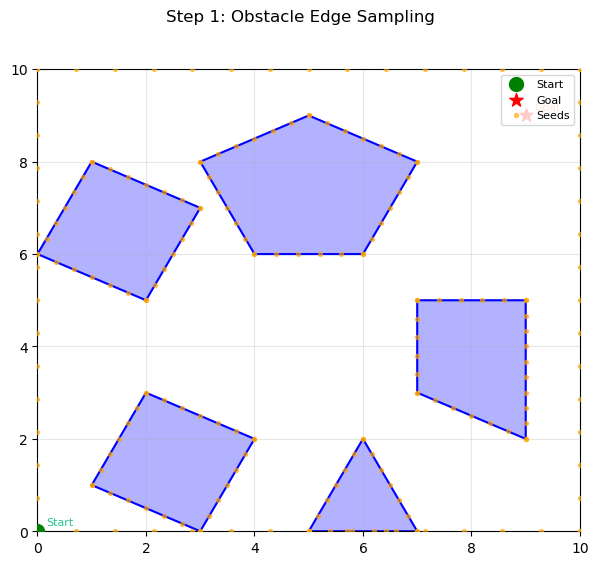

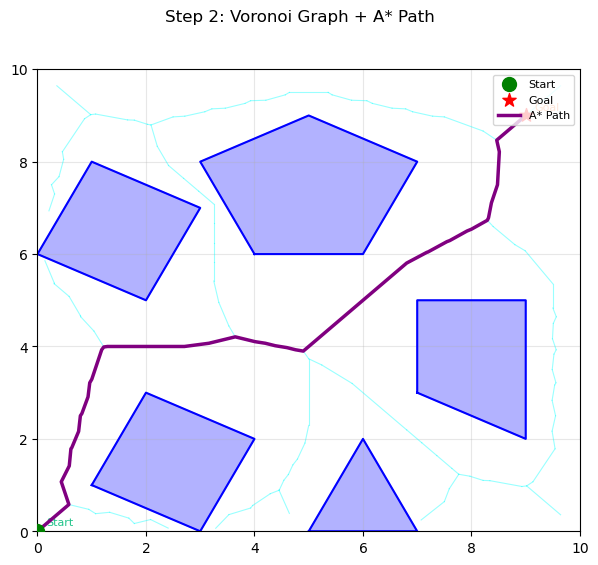

  Obstacles:     5
  Seeds:         199
  Graph nodes:   155
  Graph edges:   155
  Path waypoints:44
  Path length:   15.09


In [52]:
# Scenario 7 - Many obstacles: mix of shapes
obstacles = [
    [(1, 1), (3, 0), (4, 2), (2, 3)],
    [(5, 0), (7, 0), (6, 2)],
    [(7, 3), (9, 2), (9, 5), (7, 5)],
    [(0, 6), (2, 5), (3, 7), (1, 8)],
    [(4, 6), (6, 6), (7, 8), (5, 9), (3, 8)],
]
start = (0, 0)
goal = (9, 9)
run(obstacles, start, goal);

### Results Summary

The table below summarizes the output of each scenario after running the algorithm:

| Scenario | Obstacles | Path Found | Path Length | Waypoints | Notes |
|---|---|---|---|---|---|
| 1: Basic | 2 | ✅ | 12.67 | 41 | Simple layout, moderate path length expected |
| 2: Narrow Corridor | 2 | ✅ | 12.52 | 39 | Shorter path than basic despite corridor, Voronoi found an efficient route through the gap |
| 3: Mixed Shapes | 3 | ✅ | 11.51 | 36 | Shortest path and fewest waypoints, irregular shapes leave more open space to navigate |
| 4: Vertical Barriers | 2 | ✅ | 16.33 | 54 | Longest path and most waypoints, barriers force the largest detour around blocking structures |
| 5: Diagonal Path | 2 | ✅ | 15.78 | 45 | Long diagonal route with moderate waypoints, obstacles cause slight deviation from straight line |
| 6: Blocked Wall | 1 | ❌ | — | — | Correctly returns no path |
| 7: Dense Environment | 5 | ✅ | 15.09 | 44 | 5 obstacles but path length and waypoints are comparable to simpler scenarios, algorithm scales well |

### Key Observations

- **Correctness:** The algorithm successfully found valid paths in all solvable scenarios and correctly detected failure in Scenario 6 (blocked wall), returning no path instead of an invalid route.
- **Path length vs. complexity:** Path length is influenced more by obstacle *placement* than by obstacle *count* — Scenario 3 has 3 obstacles yet produces the shortest path, while Scenario 4 has only 2 obstacles but forces the longest detour due to their blocking positions.
- **Narrow passage (Scenario 2):** The algorithm navigates the corridor successfully, though the path may be longer than the straight-line distance due to Voronoi edges staying equidistant from both walls.
- **Irregular geometries (Scenario 3):** The Voronoi construction handles mixed polygon shapes correctly, confirming that the approach is not limited to simple rectangular obstacles.
- **Dense environment (Scenario 7):** The algorithm remains robust even with 5 obstacles, demonstrating that the graph construction and A* search scale appropriately.

## Conclusion
The Voronoi-based path planning algorithm successfully found valid paths in all solvable scenarios and correctly returned no path in the blocked scenario. The approach maximizes
clearance from obstacles by construction, making it suitable for
environments where safety margins are important.

### Limitations
- Can suggest inefficient detours in wide open spaces
- Path smoothness depends on seed density (SAMPLE_DIST)
- Currently limited to 2D static environments

### Future Work
- Path smoothing post-processing
- Extension to 3D environments
- Support for dynamic obstacles